In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score

N_TRAIN, N_TEST, P, SIGMA = 100, 2000, 10, 5.0
BETA = np.array([3, 2, 1.5, 1, 0.5, 0, 0, 0, 0, 0])
RHOS = [0.0, 0.3, 0.6, 0.9]
SEEDS = range(50)
ALPHAS = [0.001, 0.01, 0.1, 1, 10, 100, 1000]

def make_data(rho, n, rng):
    cov = np.full((P, P), rho)
    np.fill_diagonal(cov, 1.0)
    L = np.linalg.cholesky(cov)
    X = rng.standard_normal((n, P)) @ L.T
    y = X @ BETA + rng.normal(0, SIGMA, n)
    return X, y

In [2]:
rows = []
for rho in RHOS:
    for seed in SEEDS:
        X_tr, y_tr = make_data(rho, N_TRAIN, np.random.RandomState(seed))
        X_te, y_te = make_data(rho, N_TEST, np.random.RandomState(10_000 + seed))

        kf = KFold(n_splits=5, shuffle=True, random_state=seed)
        models = {
            "LinearRegression": LinearRegression(),
            "Ridge": RidgeCV(alphas=ALPHAS, cv=kf, scoring="neg_mean_squared_error"),
            "Lasso": LassoCV(alphas=ALPHAS, cv=kf, max_iter=100000),
        }
        for name, m in models.items():
            m.fit(X_tr, y_tr)
            pred = m.predict(X_te)
            coef = m.coef_
            rows.append({
                "rho": rho, "seed": seed, "model": name,
                "test_RMSE": np.sqrt(mean_squared_error(y_te, pred)),
                "test_R2": r2_score(y_te, pred),
                "alpha": getattr(m, "alpha_", np.nan),
                "coef_error": np.linalg.norm(coef - BETA),   # distance from the truth
                "coef_norm": np.linalg.norm(coef),
                "n_zero": int((coef == 0).sum()),
                **{f"c{i}": coef[i] for i in range(P)},
            })

df = pd.DataFrame(rows)
df.to_csv("D:/Research Project/results/tables/feature_corr_raw.csv", index=False)
df.shape   # (600, ...)

(600, 19)

In [3]:
coef_cols = [f"c{i}" for i in range(P)]

summary = (df.groupby(["model", "rho"])
    .agg(RMSE_mean=("test_RMSE", "mean"), RMSE_std=("test_RMSE", "std"),
         R2_mean=("test_R2", "mean"), R2_std=("test_R2", "std"),
         coef_error_mean=("coef_error", "mean"), coef_error_std=("coef_error", "std"),
         coef_norm_mean=("coef_norm", "mean"),
         median_alpha=("alpha", "median"), mean_zeros=("n_zero", "mean"))
    .reset_index())

# Coefficient variability: std of each coefficient across seeds, averaged over features
variability = (df.groupby(["model", "rho"])[coef_cols].std().mean(axis=1)
               .rename("mean_coef_std").reset_index())
summary = summary.merge(variability, on=["model", "rho"])
summary.to_csv("D:/Research Project/results/tables/feature_corr_summary.csv", index=False)
summary.round(3)

,model,rho,RMSE_mean,RMSE_std,R2_mean,R2_std,coef_error_mean,coef_error_std,coef_norm_mean,median_alpha,mean_zeros,mean_coef_std
0,Lasso,0.0,5.303,0.171,0.321,0.048,1.606,0.499,3.869,0.1,1.70,0.499
1,Lasso,0.3,5.290,0.137,0.497,0.029,1.670,0.391,3.965,0.1,2.02,0.516
2,Lasso,0.6,5.264,0.132,0.603,0.021,2.001,0.483,4.065,0.1,2.42,0.616
3,Lasso,0.9,5.208,0.123,0.677,0.016,3.262,0.927,4.428,0.1,3.98,0.983
4,LinearRegression,0.0,5.312,0.139,0.320,0.036,1.636,0.362,4.350,NaN,0.00,0.527
5,LinearRegression,0.3,5.312,0.139,0.493,0.029,1.874,0.425,4.425,NaN,0.00,0.604
6,LinearRegression,0.6,5.312,0.139,0.595,0.024,2.444,0.556,4.683,NaN,0.00,0.788
7,LinearRegression,0.9,5.312,0.139,0.664,0.020,4.834,1.108,6.246,NaN,0.00,1.559
8,Ridge,0.0,5.283,0.133,0.327,0.033,1.552,0.356,3.888,10.0,0.00,0.481
9,Ridge,0.3,5.269,0.128,0.501,0.026,1.706,0.355,3.945,10.0,0.00,0.523


In [4]:
mean_coefs = (df[df.rho == 0.9].groupby("model")[coef_cols].mean().T)
mean_coefs.insert(0, "true_beta", BETA)
std_coefs = df[df.rho == 0.9].groupby("model")[coef_cols].std().T.add_suffix("_std")
pd.concat([mean_coefs, std_coefs], axis=1).round(2)

model,true_beta,Lasso,LinearRegression,Ridge,Lasso_std,LinearRegression_std,Ridge_std
c0,3.0,2.34,2.89,1.70,1.29,1.52,0.78
c1,2.0,1.48,2.07,1.35,1.16,1.46,0.70
c2,1.5,0.81,1.04,0.91,1.19,1.55,0.95
c3,1.0,1.17,1.44,1.10,1.19,1.67,0.78
c4,0.5,0.53,0.51,0.70,0.86,1.57,0.69
c5,0.0,0.29,-0.16,0.34,0.98,1.79,0.81
c6,0.0,0.17,0.12,0.40,0.75,1.45,0.72
c7,0.0,0.13,-0.21,0.33,0.77,1.43,0.65
c8,0.0,0.25,-0.06,0.39,0.75,1.47,0.67
c9,0.0,0.46,0.33,0.58,0.88,1.69,0.73


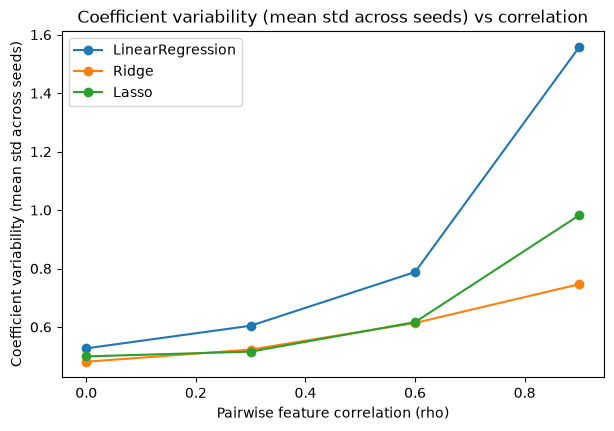

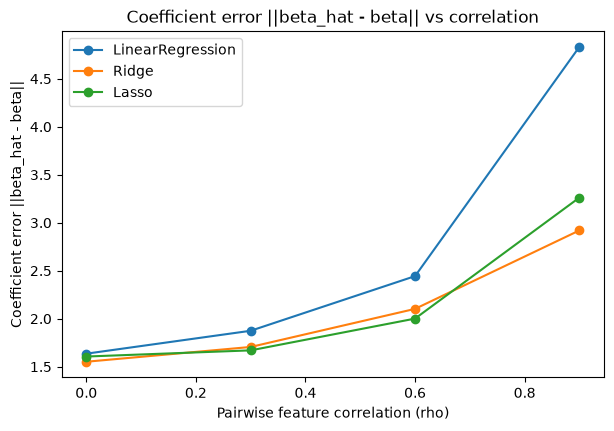

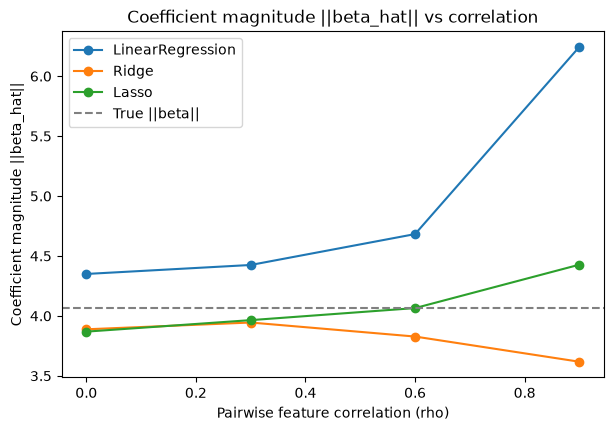

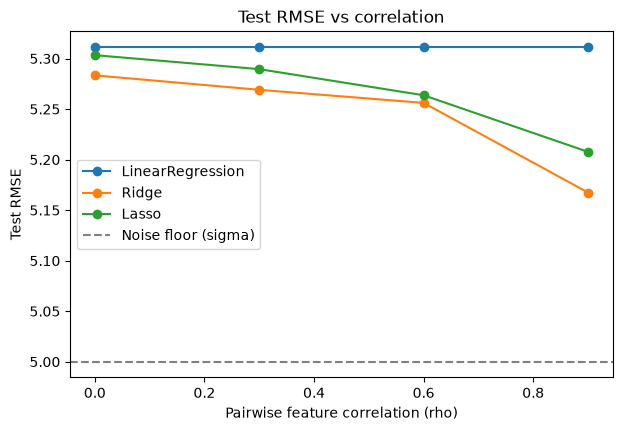

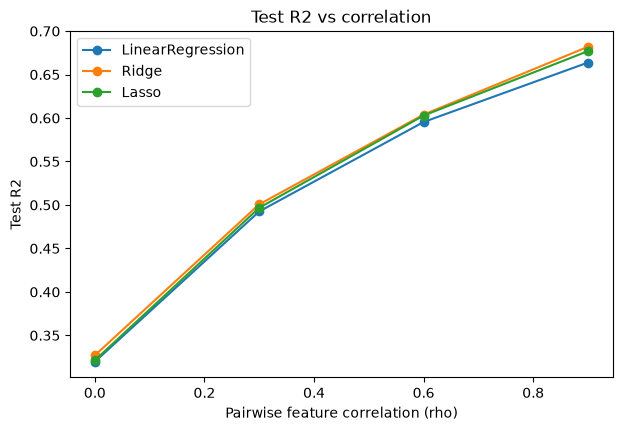

In [5]:
def plot_vs_rho(col, ylabel, fname, hline=None, hlabel=None):
    plt.figure(figsize=(7, 4.5))
    for name in ["LinearRegression", "Ridge", "Lasso"]:
        d = summary[summary.model == name]
        plt.plot(d.rho, d[col], marker="o", label=name)
    if hline is not None:
        plt.axhline(hline, color="gray", linestyle="--", label=hlabel)
    plt.xlabel("Pairwise feature correlation (rho)")
    plt.ylabel(ylabel)
    plt.title(f"{ylabel} vs correlation")
    plt.legend()
    plt.savefig(f"D:/Research Project/results/figures/{fname}", dpi=150, bbox_inches="tight")
    plt.show()

plot_vs_rho("mean_coef_std", "Coefficient variability (mean std across seeds)", "corr_coef_variability.png")
plot_vs_rho("coef_error_mean", "Coefficient error ||beta_hat - beta||", "corr_coef_error.png")
plot_vs_rho("coef_norm_mean", "Coefficient magnitude ||beta_hat||", "corr_coef_norm.png",
            hline=np.linalg.norm(BETA), hlabel="True ||beta||")
plot_vs_rho("RMSE_mean", "Test RMSE", "corr_test_rmse.png", hline=SIGMA, hlabel="Noise floor (sigma)")
plot_vs_rho("R2_mean", "Test R2", "corr_test_r2.png")

In [6]:
piv = df.pivot_table(index=["rho", "seed"], columns="model",
                     values=["coef_error", "test_RMSE"])
gain = pd.DataFrame({
    "Ridge_coef_gain": piv["coef_error"]["LinearRegression"] - piv["coef_error"]["Ridge"],
    "Lasso_coef_gain": piv["coef_error"]["LinearRegression"] - piv["coef_error"]["Lasso"],
    "Ridge_rmse_gain": piv["test_RMSE"]["LinearRegression"] - piv["test_RMSE"]["Ridge"],
    "Lasso_rmse_gain": piv["test_RMSE"]["LinearRegression"] - piv["test_RMSE"]["Lasso"],
})
g = gain.groupby(level="rho")
paired = pd.concat([g.mean().add_suffix("_mean"),
                    g.agg(lambda s: (s > 0).mean()).add_suffix("_winrate")], axis=1).round(3)
paired.to_csv("D:/Research Project/results/tables/feature_corr_paired_gain.csv")
paired

,Ridge_coef_gain_mean,Lasso_coef_gain_mean,Ridge_rmse_gain_mean,Lasso_rmse_gain_mean,Ridge_coef_gain_winrate,Lasso_coef_gain_winrate,Ridge_rmse_gain_winrate,Lasso_rmse_gain_winrate
rho,,,,,,,,
0.0,0.084,0.030,0.028,0.008,0.74,0.82,0.72,0.86
0.3,0.169,0.204,0.043,0.022,0.84,0.92,0.76,0.82
0.6,0.341,0.442,0.056,0.048,0.84,0.98,0.84,0.82
0.9,1.913,1.571,0.144,0.104,0.98,1.00,0.90,0.86


In [7]:
las = df[df.model == "Lasso"].copy()
true_cols  = [f"c{i}" for i in range(5)]    # true nonzero features
noise_cols = [f"c{i}" for i in range(5, 10)] # true zero features
las["true_kept"]  = (las[true_cols]  != 0).sum(axis=1)
las["noise_kept"] = (las[noise_cols] != 0).sum(axis=1)
las.groupby("rho")[["true_kept", "noise_kept"]].mean().round(2)

,true_kept,noise_kept
rho,,
0.0,4.56,3.74
0.3,4.58,3.40
0.6,4.44,3.14
0.9,3.74,2.28


# Phase 5: Controlled feature-correlation study (RQ3)

**Question:** Do Ridge and Lasso stabilize coefficients under strong multicollinearity, and how does feature correlation affect LinearRegression, Ridge, and Lasso?

## Protocol
- **Data-generating process:** X ~ multivariate normal, 10 features, unit variance, equal pairwise correlation rho; y = X·beta + Normal(0, sigma²).
- **True beta:** [3, 2, 1.5, 1, 0.5, 0, 0, 0, 0, 0] (5 informative features, 5 pure-noise features), so ||beta|| ≈ 4.06.
- **Independent variable:** rho ∈ {0.0, 0.3, 0.6, 0.9}. I interpret the guide's "correlation levels" as the pairwise correlation between features.
- **Held fixed:** n_train = 100, p = 10, sigma = 5, beta, and the alpha grid [0.001 ... 1000].
- **Test data:** a fresh 2000-row test set drawn from the same process for every run (noise floor RMSE = sigma = 5).
- **Models:** LinearRegression, RidgeCV, LassoCV. Alpha is chosen by 5-fold shuffled CV on the training data only, with the same rule for every model and every rho.
- **Repetitions:** 50 seeds per condition. The same seeds are reused across rho, so the comparison is paired.
- **Metrics:** test RMSE, test R², coefficient variability (std of each coefficient across seeds, averaged over features), coefficient error ||beta_hat − beta||, coefficient norm ||beta_hat||, and number of zeroed coefficients.
- **Metric caveat:** the signal variance grows with rho (≈16.5 at rho=0 to ≈59.3 at rho=0.9) while the noise stays fixed, so R² rises with rho for every model. R² is only comparable within one rho level. Cross-rho conclusions use RMSE and coefficient error.
- **Scope:** this is a controlled experiment, not a claim that any rho is realistic for real data.

## Phase 5 observations

1. **Coefficients of LinearRegression become much less stable as rho rises.** Mean coefficient std across seeds goes 0.527 → 0.604 → 0.788 → 1.559 (rho 0 → 0.9, about 3x). Coefficient error ||beta_hat − beta|| goes 1.64 → 4.83, and the coefficient norm inflates to 6.25 (true norm 4.06).
2. **Ridge and Lasso reduce this instability, and Ridge reduces it more.** At rho=0.9, variability is 1.559 (OLS), 0.983 (Lasso), 0.746 (Ridge), which is about 37% and 52% lower than OLS. Growth from rho=0 to 0.9 is about 3.0x (OLS), 2.0x (Lasso), 1.6x (Ridge). At rho=0 the three models are about equal, so the benefit appears only as correlation rises.
3. **Total coefficient error is lower with regularization at rho=0.9** (OLS 4.83, Lasso 3.26, Ridge 2.92), even though shrinkage adds bias. At rho=0.9 Ridge shrinks the true coefficients (e.g. c0: 1.70 vs true 3.0) and gives weight to true-zero features (mean 0.33-0.58), while OLS is close to unbiased on average (c0: 2.89) but very noisy (std ≈ 1.5).
4. **Neither regularized model recovers the true sparse structure.** Both leave non-zero weight on the noise features on average. Lasso zeroed more coefficients as rho increased (mean zeros 1.70 → 3.98 of 10), but this count does not show whether the zeroed features were the true-zero ones.
5. **Prediction error barely changes.** OLS test RMSE is 5.312 at every rho, against a noise floor of 5.0. Ridge improves to 5.167 and Lasso to 5.208 at rho=0.9 (about 3% or less), with almost no difference at rho=0. Multicollinearity damages coefficient estimates far more than predictions in this setup.
6. **OLS RMSE is identical across rho by construction, not by error.** OLS predictions are invariant to invertible linear transformations of the features, and the same seeds generate the same underlying draws at each rho.
7. **Chosen alphas did not change with rho** (median Ridge alpha = 10, Lasso alpha = 0.1), though the alpha grid is coarse.

**Conclusion:** in this setup (n=100, p=10, sigma=5, one beta), stronger feature correlation made OLS coefficients about 3x less stable and about 3x further from the truth without hurting its predictions. Ridge and Lasso stabilized the coefficients, Ridge more than Lasso, at the cost of shrinkage bias and without recovering the true sparse model.

**Limitations:** one data-generating configuration, equal pairwise correlation only, 50 seeds, a coarse alpha grid, and results from this synthetic setting should not be taken to describe real data.

In [8]:
import sys; sys.path.append("../src")
from experiment_log import save_experiment_record, audit, lookup, NA

In [9]:
save_experiment_record(
    "exp4_feature_correlation", "Controlled feature-correlation study (synthetic)",
    dataset={"type": "synthetic multivariate normal", "n_train": N_TRAIN, "n_test": N_TEST,
             "n_features": P, "noise_sigma": SIGMA, "true_beta": list(BETA), "rho_levels": RHOS},
    preprocessing="None (features generated with unit variance)",
    seeds={"train_seeds": list(SEEDS), "test_seed_offset": 10000},
    models={"LinearRegression": "default", "RidgeCV": {"alphas": ALPHAS},
            "LassoCV": {"alphas": ALPHAS, "max_iter": 100000}},
    train_test_protocol="Fresh training set and independent large test set per seed and rho; same seeds reused across rho (paired)",
    cv_protocol="RidgeCV/LassoCV with 5-fold shuffled KFold (random_state = seed) on training data only",
    metrics=summary,
    tables=["feature_corr_raw.csv", "feature_corr_summary.csv"],
    figures=["corr_coef_variability.png", "corr_coef_error.png", "corr_coef_norm.png",
             "corr_test_rmse.png", "corr_test_r2.png"],
    observation="OLS coefficients became much less stable as correlation increased while its predictions did not change. Ridge and Lasso reduced the instability, Ridge more than Lasso, at the cost of shrinkage bias, and neither recovered the true sparse structure.",
)

Saved results/experiments/exp4_feature_correlation.json and .md


{'exp_id': 'exp4_feature_correlation',
 'title': 'Controlled feature-correlation study (synthetic)',
 'created': '2026-10-13T01:32:55',
 'dataset': {'type': 'synthetic multivariate normal',
  'n_train': 100,
  'n_test': 2000,
  'n_features': 10,
  'noise_sigma': 5.0,
  'true_beta': [3.0, 2.0, 1.5, 1.0, 0.5, 0.0, 0.0, 0.0, 0.0, 0.0],
  'rho_levels': [0.0, 0.3, 0.6, 0.9]},
 'preprocessing': 'None (features generated with unit variance)',
 'seeds': {'train_seeds': [0,
   1,
   2,
   3,
   4,
   5,
   6,
   7,
   8,
   9,
   10,
   11,
   12,
   13,
   14,
   15,
   16,
   17,
   18,
   19,
   20,
   21,
   22,
   23,
   24,
   25,
   26,
   27,
   28,
   29,
   30,
   31,
   32,
   33,
   34,
   35,
   36,
   37,
   38,
   39,
   40,
   41,
   42,
   43,
   44,
   45,
   46,
   47,
   48,
   49],
  'test_seed_offset': 10000},
 'models': {'LinearRegression': 'default',
  'RidgeCV': {'alphas': [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
  'LassoCV': {'alphas': [0.001, 0.01, 0.1, 1, 10, 100, 1000